<a href="https://colab.research.google.com/github/natenorris10/MAT-422/blob/main/HW_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Calculus and Optimization Homework - 3.3

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize_scalar, basinhopping

###3.3.1 - Necessary and Sufficient Conditions of Local Minimizers

To optimize a function, the goal is usually to find the global minimum.  A global minimum of a function $f: \mathbb{R}^d \to \mathbb{R}$ is a point $f(\mathbf{x}^*) \in \mathbb{R}$ such that for all $\mathbf{x} \in \mathbb{R}^d, f(\mathbf{x}^*) \leq f(\mathbf{x})$

Typically, it's not likely we find the global minimum, so  we instead look for a local minimum.  A local minimum of a function $f:\mathbb{R}^d \to \mathbb{R}$ is a point $\mathbf{x}^* \in \mathbb{R}^d$ where there exists a $δ > 0$ such that $f(\mathbf{x}^*) \leq f(\mathbf{x}), ∀\mathbf{x} \in B_{δ}(\mathbf{x}^*) \backslash \{\mathbf{x}^*\}$

In [27]:
# Defining function and finding local/global minimums
xvals = np.linspace(-6, 6, 200)

def function1(x):
  return (1/4)*x**4 + (3/4)*x**3 - (1/2)*x**2 - x - 3

local_min = minimize_scalar(function1)
local_x = local_min["x"]
local_y = local_min["fun"]

global_min = basinhopping(function1, -3)
global_x = global_min["x"][0]
global_y = global_min["fun"]

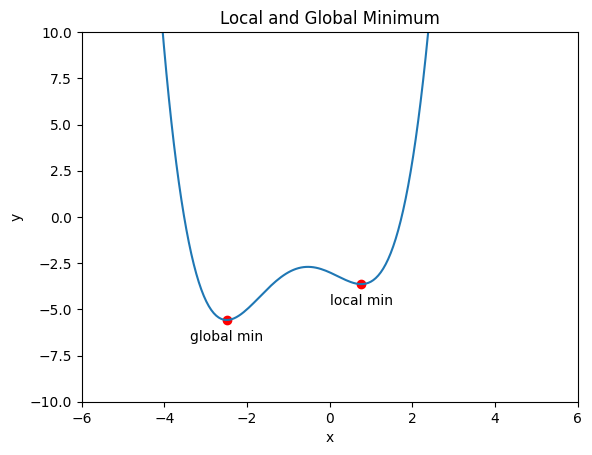

In [33]:
# Plotting results
plt.plot(xvals, function1(xvals))
plt.scatter([local_x, global_x], [local_y, global_y], c="red")

plt.annotate("global min", (global_x, global_y), textcoords="offset points",
             xytext=(0, -15), ha="center")
plt.annotate("local min", (local_x, local_y), textcoords="offset points",
             xytext=(0, -15), ha="center")

plt.ylim(-10, 10)
plt.xlim(-6, 6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Local and Global Minimum")
plt.show()

###3.3.2 - Convexity and Global Minimizers

A convex function is a function $f:\mathbb{R}^d \to \mathbb{R}$ where for all $\mathbf{x}, \mathbf{y} \in \mathbb{R}^d$ and all $α \in [0,1],$ <br>
$f((1-α)\mathbf{x} + α\mathbf{y}) \leq (1-α)f(\mathbf{x}) + αf(\mathbf{y})$

In [29]:
# Defining function and interpolating
def function2(x):
  return np.exp(x)

y0 = function2(2)
y1 = function2(5.5)

t = 0.6
line_x = (1-t)*2 + t*5.5
line_y = (1-t)*y0 + t*y1

confunc_y = function2(line_x)

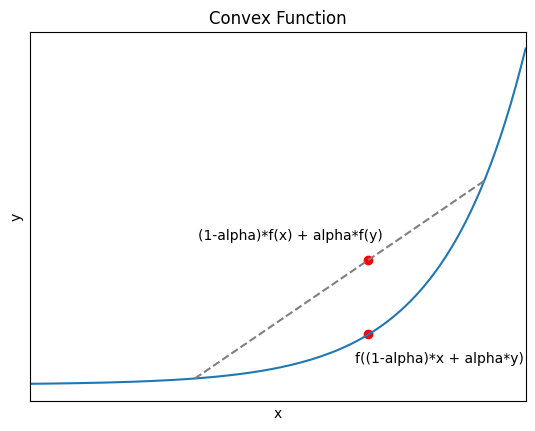

In [32]:
# Plotting results
plt.plot(xvals, function2(xvals))
plt.plot([2, 5.5], [y0, y1], color="gray", linestyle="dashed")
plt.scatter([line_x, line_x], [line_y, confunc_y], color="red")

plt.annotate("(1-alpha)*f(x) + alpha*f(y)", (line_x, line_y),
             textcoords="offset points", xytext=(10, 15), ha="right")
plt.annotate("f((1-alpha)*x + alpha*y)", (line_x, confunc_y),
             textcoords="offset points", xytext=(-10, -20), ha="left")

plt.xticks([])
plt.yticks([])
plt.xlim(0, 6)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Convex Function")
plt.show()

###3.3.3 - Gradient Descent

Gradient descent is a method of finding a local minimum of a differentiable function.  This is done by finding the steepest gradiant, or $-∇f$, and following it down until it "flattens out" to a minimum.

In [3]:
# Defining functions
def function3(x, y):
  return x**2 + 3*y**2

def grad_f(x, y):
  return np.array([2*x, 6*y])

In [4]:
# Running the gradient descent
start = np.array([-4.0, 3.0])
alpha = 0.1
n_steps = 30

path = [start]
p = start.copy()

for i in range(n_steps):
  p = p - alpha*grad_f(*p)
  path.append(p)

path = np.array(path)
z_path = function3(*path.T)

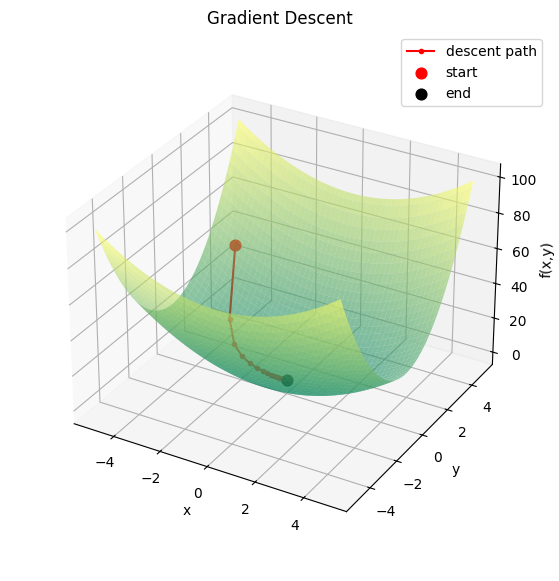

In [25]:
# Plotting the function
xs = np.linspace(-5, 5, 100)
ys = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(xs, ys)
Z = function3(X, Y)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap="summer", alpha=0.6)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x,y)")
ax.set_title("Gradient Descent")

# Drawing path of descent
ax.plot(*path.T, z_path + 0.5, "r.-", label="descent path")
ax.scatter(*path[0], z_path[0] + 0.5, color="red", s=60, label="start")
ax.scatter(*path[-1], z_path[-1] + 0.5, color="black", s=60, label="end")
ax.legend()

ax.set_box_aspect(None, zoom=0.9)
plt.show()